<div align="center">

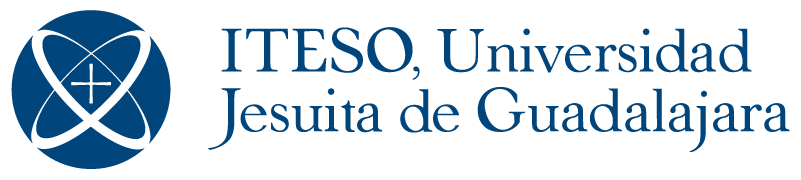

<br><br>

# Proyecto Final — Análisis Estadístico Multivariable

### Predicción del tiempo de recuperación de fallas de comunicación en la infraestructura semafórica del Área Metropolitana de Monterrey

<br>

**Ruta metodológica A — Regresión Lineal Múltiple**

Otoño 2026 · Prof. Luis Alvarado

<br>

*Integrantes:* `(completar)`

<br>

</div>

---

## 1. Contexto del caso

### 1.1 La plataforma y el problema real

**OptiVía** es una plataforma de gestión de movilidad que se renta a gobiernos municipales.
Entre otras cosas, monitorea en tiempo real el estado de comunicación de la infraestructura
vial instalada en campo: controladores de semáforos, paneles de mensaje variable y sensores.
Cuando un equipo deja de responder, la plataforma abre automáticamente un registro de **caída**
con el momento de inicio, y lo cierra cuando el equipo vuelve a comunicarse.

Este proyecto usa los **datos históricos reales del despliegue de Monterrey**, que cubre nueve
municipios del Área Metropolitana: Monterrey, San Pedro, San Nicolás, Apodaca, Escobedo,
Guadalupe, Santa Catarina, García y Juárez.

### 1.2 Por qué esto le importa al municipio

El indicador que mide la calidad del mantenimiento de una red semafórica es el **MTTR**
(*Mean Time To Repair*): cuánto tarda en promedio un equipo caído en volver a operar. Mientras
un controlador está caído, el centro de control pierde la capacidad de ajustar tiempos, de
detectar fallas en campo y de sincronizar el corredor. El costo lo paga el ciudadano en
tiempo de viaje.

Hoy la asignación de cuadrillas se hace por orden de llegada. Si se pudiera **estimar al
momento de la detección** cuánto va a tardar una caída en resolverse, la coordinación operativa
podría priorizar, fijar metas de atención diferenciadas por municipio y detectar temprano los
casos que se van a convertir en caídas largas.

### 1.3 Pregunta de negocio

> **¿Qué factores conocidos en el momento en que se detecta una caída de comunicación explican
> cuánto tardará el equipo en recuperarse, y con qué precisión puede estimarse esa duración?**

### 1.4 Nota metodológica sobre la causa

La variable `causa` (equipo / energía-GPRS / indeterminado) se verificó contra la base antes de
incluirla como predictor, porque si se asignara al cerrar la caída sería información del futuro.
La verificación confirmó que **se asigna en la detección**: el 100 % de las caídas abiertas con
menos de una hora de antigüedad ya tiene causa registrada, y los campos `causa` y `causa_fin`
discrepan en unos 44,400 registros históricos, lo cual sólo es posible si se escriben en dos
momentos distintos. El modelo es por tanto un predictor real y no una explicación retrospectiva.

### 1.5 Sobre el poder explicativo esperado

Las correlaciones simples de los predictores continuos con la duración son débiles, de modo que
se anticipa un coeficiente de determinación bajo. **Este punto se consultó con el profesor y
quedó confirmado que un $R^2$ bajo no es un problema** siempre que el análisis esté bien
fundamentado y la interpretación sea honesta.

Y es que la magnitud del $R^2$ es, en sí misma, parte del hallazgo. Si las características
observables al detectar la falla explican poco de la duración, la conclusión de negocio es que
el MTTR está dominado por factores del *proceso de respuesta* —disponibilidad de cuadrilla,
refacciones, acceso al sitio— que la plataforma todavía no mide. Eso es una recomendación
accionable: hay que instrumentar la respuesta, no sólo el diagnóstico.

---
## 2. Preparación del entorno y carga de datos

In [ ]:
# Librerias del proyecto.
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import anova_lm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

from sklearn.preprocessing import PowerTransformer, StandardScaler

warnings.filterwarnings("ignore")

# Semilla unica para todo el proyecto (requisito de reproducibilidad de la rubrica).
SEMILLA = 42
np.random.seed(SEMILLA)

# Estilo de las graficas.
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

print(f"pandas {pd.__version__} | numpy {np.__version__} | statsmodels {sm.__version__}")

In [ ]:
# Carga del dataset. Acepta el archivo como .csv o .xlsx sin que haya que tocar el codigo.
from pathlib import Path

NOMBRE_BASE = "Data_AEM_mttr"

def carga_datos(nombre_base):
    """Busca el archivo del proyecto en varias extensiones y rutas comunes."""
    candidatos = []
    for carpeta in [Path("."), Path("datos"), Path("data"), Path("..")]:
        for ext in [".csv", ".xlsx", ".xls"]:
            candidatos.append(carpeta / f"{nombre_base}{ext}")

    for ruta in candidatos:
        if ruta.exists():
            datos = pd.read_csv(ruta) if ruta.suffix == ".csv" else pd.read_excel(ruta)
            print(f"Archivo cargado: {ruta}")
            return datos

    raise FileNotFoundError(
        f"No se encontro '{nombre_base}' (.csv o .xlsx). "
        f"Colocalo junto al notebook o en una subcarpeta 'datos/'."
    )

poblacion = carga_datos(NOMBRE_BASE)
print(f"Dimensiones: {poblacion.shape[0]} observaciones x {poblacion.shape[1]} variables")
poblacion.head()

### 2.1 Diccionario de variables

El archivo es una extracción de la base de producción de OptiVía (proyecto Supabase de
Monterrey), tomada el 18 de noviembre de 2026. Cubre caídas **ya cerradas** entre el 21 de
junio y el 18 de noviembre de 2026, con duración entre 1 minuto y 7 días y causa registrada.

| Variable | Tipo | Descripción |
|---|---|---|
| `caida_id` | identificador | Clave del registro de caída |
| `municipio` | categórica (9) | Municipio donde está instalado el equipo |
| `tipo_equipo` | categórica (3) | `cc` controlador, `bl` sensor Bluetooth, `pmv` panel de mensaje variable |
| `causa` | categórica (3) | Diagnóstico al detectar: `equipo`, `energia_gprs`, `indeterminado` |
| `tipo_dia` | categórica (3) | `lv` lunes a viernes, `sab`, `dom` |
| `turno` | categórica (3) | `matutino` 6–13 h, `vespertino` 14–21 h, `nocturno` 22–5 h |
| `hora_inicio` | continua | Hora local de inicio de la caída (0–23) |
| `dia_semana_num` | continua | 0 = domingo … 6 = sábado |
| `caidas_elemento` | continua | Total de caídas de ese equipo en el periodo (fragilidad histórica) |
| `duracion_media_otras_min` | continua | Duración media de las **otras** caídas del mismo equipo (*leave-one-out*, sin fuga de información) |
| `duracion_min` | continua | **Duración de la caída en minutos** |
| `log_duracion_min` | continua | **Variable dependiente**: logaritmo natural de la duración |

**Variables adicionales incluidas deliberadamente.** Las siguientes son variables reales de la
base que no tienen una razón sustantiva clara para predecir la duración de una falla. Se
incluyen para que el proceso de **selección de variables tenga que descartarlas con criterio
estadístico**, en lugar de partir de un conjunto ya depurado a mano:

| Variable | Tipo | Descripción |
|---|---|---|
| `lat`, `lng` | continuas | Coordenadas geográficas del equipo |
| `dia_mes` | continua | Día del mes (1–31) |
| `semana_anio` | continua | Semana del año |
| `antiguedad_elemento_dias` | continua | Días entre el alta del equipo en OptiVía y la caída |
| `num_ips_elemento` | continua | Número de direcciones IP configuradas en el equipo |
| `linea_gertrude` | continua | Número de línea del equipo en el sistema GERTRUDE (identificador administrativo) |

In [ ]:
poblacion.info()

In [ ]:
# Valores faltantes y duplicados.
faltantes = poblacion.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

if len(faltantes):
    display(pd.DataFrame({
        "faltantes": faltantes,
        "porcentaje": (100 * faltantes / len(poblacion)).round(2),
    }))
else:
    print("Sin valores faltantes.")

print(f"\nFilas duplicadas: {poblacion.duplicated().sum()}")

#### Decisiones de limpieza previas al muestreo

1. **`linea_gertrude` se descarta por razón sustantiva.** Es un identificador administrativo con
   cientos de valores distintos; un número de línea más alto no significa "más" de nada. Además
   es la variable con más faltantes. Se elimina por argumento de contenido, no estadístico. Las
   otras seis variables adicionales sí pasan a la selección estadística.

2. **`tipo_equipo` se colapsa a dos niveles.** Los niveles `bl` (63 casos) y `pmv` (25 casos)
   representan juntos menos del 2 % de los registros; en una muestra de ~356 observaciones
   quedarían con un puñado de casos y los contrastes serían inestables. Se agrupan en `otro`.

3. **Las filas con `duracion_media_otras_min` faltante se eliminan.** Corresponden a equipos con
   una sola caída registrada, para los cuales el promedio *leave-one-out* no está definido.

In [ ]:
# 1) Descarte del identificador administrativo.
poblacion = poblacion.drop(columns=["linea_gertrude"])

# 2) Colapso de los niveles raros de tipo_equipo.
print("Antes del colapso:")
print(poblacion["tipo_equipo"].value_counts().to_string())

poblacion["tipo_equipo"] = np.where(poblacion["tipo_equipo"] == "cc", "cc", "otro")

print("\nDespues del colapso:")
print(poblacion["tipo_equipo"].value_counts().to_string())

# 3) Eliminacion de filas sin promedio leave-one-out definido.
antes = len(poblacion)
poblacion = poblacion.dropna(subset=["duracion_media_otras_min"]).reset_index(drop=True)
print(f"\nFilas eliminadas por faltantes: {antes - len(poblacion)}")
print(f"Poblacion final: {len(poblacion)} observaciones")

---
## 3. Definición de la población y muestreo

### 3.1 Población

La población es el conjunto de **caídas de comunicación cerradas de los equipos de campo de
OptiVía en los nueve municipios del Área Metropolitana de Monterrey, entre el 21 de junio y el
18 de noviembre de 2026**, con duración entre 1 minuto y 7 días y causa registrada.

Una precisión necesaria para la ficha: el archivo que se analiza no es el censo completo de la
base, sino un **marco muestral sistemático** extraído de ella (se tomó 1 de cada 60 registros
por identificador, de un universo de alrededor de 280,000 caídas). Sobre ese marco se aplica
después el muestreo aleatorio simple que pide la rúbrica. Se declara así por transparencia: el
muestreo sistemático previo recorre todo el rango de identificadores y por lo tanto todo el
periodo, sin concentrarse en ninguna ventana temporal.

### 3.2 Tamaño de muestra

Se usa la fórmula para poblaciones finitas con nivel de confianza del 95 % ($z = 1.96$),
$p = 0.5$ para máxima varianza y margen de error $e = 0.05$:

$$ n = \frac{N \, z^{2} \, p(1-p)}{e^{2}(N-1) + z^{2} \, p(1-p)} $$

In [ ]:
def tamano_muestra(n_poblacion, z=1.96, p=0.5, error=0.05):
    """Tamano de muestra para poblacion finita (rubrica, seccion 2.1)."""
    numerador = n_poblacion * (z ** 2) * p * (1 - p)
    denominador = (error ** 2) * (n_poblacion - 1) + (z ** 2) * p * (1 - p)
    return math.ceil(numerador / denominador)

N_POBLACION = len(poblacion)
N_MUESTRA = tamano_muestra(N_POBLACION)

print(f"N (poblacion) = {N_POBLACION}")
print(f"n (muestra)   = {N_MUESTRA}")
print(f"Fraccion de muestreo = {100 * N_MUESTRA / N_POBLACION:.1f}%")

In [ ]:
# Muestreo aleatorio simple con semilla fija.
muestra = poblacion.sample(n=N_MUESTRA, random_state=SEMILLA).reset_index(drop=True)

print(f"Muestra extraida: {muestra.shape[0]} observaciones x {muestra.shape[1]} variables")
muestra.head()

### 3.3 Representatividad: muestra contra población

In [ ]:
# Comparacion de medias en las variables continuas.
continuas_todas = [
    "hora_inicio", "dia_semana_num", "caidas_elemento", "duracion_media_otras_min",
    "lat", "lng", "dia_mes", "semana_anio", "antiguedad_elemento_dias",
    "num_ips_elemento", "duracion_min", "log_duracion_min",
]

comparacion = pd.DataFrame({
    "media_poblacion": poblacion[continuas_todas].mean(),
    "media_muestra": muestra[continuas_todas].mean(),
})
comparacion["dif_%"] = (
    100 * (comparacion["media_muestra"] - comparacion["media_poblacion"])
    / comparacion["media_poblacion"].abs()
)
display(comparacion.round(3))

In [ ]:
# Comparacion de proporciones en las variables categoricas.
categoricas = ["municipio", "tipo_equipo", "causa", "tipo_dia", "turno"]

for variable in categoricas:
    tabla = pd.DataFrame({
        "poblacion_%": 100 * poblacion[variable].value_counts(normalize=True),
        "muestra_%": 100 * muestra[variable].value_counts(normalize=True),
    }).round(2)
    tabla["dif_pp"] = (tabla["muestra_%"] - tabla["poblacion_%"]).round(2)
    print(f"--- {variable} ---")
    print(tabla.to_string())
    print()

In [ ]:
# Contraste formal: la variable dependiente se distribuye igual en muestra y poblacion?
# H0: ambas provienen de la misma distribucion.
ks_est, ks_p = stats.ks_2samp(muestra["log_duracion_min"], poblacion["log_duracion_min"])
print("Prueba Kolmogorov-Smirnov de dos muestras sobre log_duracion_min")
print(f"  Estadistico D = {ks_est:.4f}")
print(f"  valor p       = {ks_p:.4f}")
print()
if ks_p > 0.05:
    print("No se rechaza H0 (alfa = 0.05): la muestra es representativa de la poblacion")
    print("en la distribucion de la variable dependiente.")
else:
    print("Se rechaza H0: la muestra difiere de la poblacion. Revisar el muestreo.")

---
## 4. Flujo del análisis

### Nota sobre el orden de trabajo

La rúbrica enumera las etapas como 4.1 EDA, 4.2 correlaciones, 4.3 selección de variables y
4.4 modelo principal. Este notebook introduce **un solo cambio de orden, indicado por el
profesor: la selección de variables se ejecuta antes que el análisis de correlaciones**. El
razonamiento es de economía, porque no tiene sentido estudiar en detalle la estructura de
correlación de variables que el modelo va a descartar de todos modos.

El resto del flujo respeta la secuencia estándar, que importa: **el modelo se ajusta primero y
las transformaciones vienen después**, como corrección ante los problemas que revelen *sus
residuales*. Elegir una transformación antes de tener un modelo sería invertir el diagnóstico:
la regresión lineal no supone que la variable dependiente sea normal, sino que lo sean los
residuales, y éstos no existen hasta que hay un modelo ajustado.

Las herramientas que el profesor señaló para corregir normalidad —**escalamiento, logaritmo,
Yeo-Johnson y diagramas de dispersión**— se aplican por tanto en la sección 4.5, que es donde
corresponde.

| Sección de este notebook | Corresponde a |
|---|---|
| 4.1 Análisis exploratorio | rúbrica 4.1 |
| 4.2 Selección de variables | rúbrica 4.3 |
| 4.3 Correlaciones y covarianza | rúbrica 4.2 |
| 4.4 Modelo principal y significancia | rúbrica 4.4 |
| 4.5 Verificación de supuestos y corrección | rúbrica 4.5 |

---
## 4.1 Análisis Exploratorio de Datos  `[rúbrica 4.1]`

Todo el EDA se realiza **sobre la muestra**, conforme a la sección 2.1 de la rúbrica.

In [ ]:
# Estadisticas descriptivas de las variables numericas de la muestra.
descriptivas = muestra[continuas_todas].describe().T
descriptivas["mediana"] = muestra[continuas_todas].median()
descriptivas["rango_iq"] = descriptivas["75%"] - descriptivas["25%"]
descriptivas["asimetria"] = muestra[continuas_todas].skew()
descriptivas["curtosis"] = muestra[continuas_todas].kurtosis()

display(
    descriptivas[["count", "mean", "mediana", "std", "min", "25%", "75%", "max",
                  "rango_iq", "asimetria", "curtosis"]].round(3)
)

In [ ]:
# Frecuencias de las variables categoricas.
for variable in categoricas:
    conteo = muestra[variable].value_counts()
    porcentaje = (100 * muestra[variable].value_counts(normalize=True)).round(1)
    print(f"--- {variable} ({muestra[variable].nunique()} niveles) ---")
    print(pd.DataFrame({"n": conteo, "%": porcentaje}).to_string())
    print()

### 4.1.1 La variable dependiente

La duración en minutos es una variable de tiempo de espera: acotada por abajo, sin límite por
arriba y con una cola derecha muy larga. Se adopta **provisionalmente** el logaritmo como escala
de trabajo, que es la transformación habitual para este tipo de variable y la que permite
interpretar los coeficientes como efectos multiplicativos.

Es una elección provisional a propósito: **la decisión definitiva se toma en la sección 4.5**,
a partir de los residuales del modelo ya ajustado, que es donde el supuesto de normalidad
realmente aplica.

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

ejes[0, 0].hist(muestra["duracion_min"], bins=50, color="#c0392b", edgecolor="white")
ejes[0, 0].set_title("Duracion en minutos (escala original)")
ejes[0, 0].set_xlabel("minutos")
ejes[0, 0].set_ylabel("frecuencia")

stats.probplot(muestra["duracion_min"], dist="norm", plot=ejes[0, 1])
ejes[0, 1].set_title("Q-Q normal — escala original")

ejes[1, 0].hist(muestra["log_duracion_min"], bins=40, color="#2471a3", edgecolor="white")
ejes[1, 0].set_title("log(duracion)")
ejes[1, 0].set_xlabel("ln(minutos)")
ejes[1, 0].set_ylabel("frecuencia")

stats.probplot(muestra["log_duracion_min"], dist="norm", plot=ejes[1, 1])
ejes[1, 1].set_title("Q-Q normal — escala logaritmica")

plt.tight_layout()
plt.show()

print(f"Asimetria en minutos          : {muestra['duracion_min'].skew():.3f}")
print(f"Asimetria en logaritmo        : {muestra['log_duracion_min'].skew():.3f}")
print(f"Razon max/mediana en minutos  : {muestra['duracion_min'].max() / muestra['duracion_min'].median():.1f}")

### 4.1.2 Prueba formal de normalidad

La rúbrica indica usar **Shapiro-Wilk si $n \leq 50$ y Kolmogorov-Smirnov si $n > 50$**. Con
$n \approx 356$ corresponde Kolmogorov-Smirnov. Se agrega D'Agostino-Pearson, que la propia
rúbrica admite como alternativa y que es más sensible a la asimetría y la curtosis.

$H_0$: la variable proviene de una distribución normal.

In [ ]:
def prueba_normalidad(serie, nombre, verbose=True):
    """Aplica la prueba que corresponde segun el tamano de muestra (rubrica 4.1)."""
    x = pd.Series(serie).dropna()
    n = len(x)
    filas = []

    if n <= 50:
        est, p = stats.shapiro(x)
        filas.append(("Shapiro-Wilk", est, p))
    else:
        # KS contra una normal con los parametros estimados de la propia muestra.
        normal_ajustada = stats.norm(loc=x.mean(), scale=x.std(ddof=1))
        est, p = stats.kstest(x, normal_ajustada.cdf)
        filas.append(("Kolmogorov-Smirnov", est, p))
        est2, p2 = stats.normaltest(x)
        filas.append(("D'Agostino-Pearson", est2, p2))

    if verbose:
        print(f"=== {nombre}  (n = {n}) ===")
        for prueba, est, p in filas:
            veredicto = "no se rechaza H0" if p > 0.05 else "SE RECHAZA H0"
            print(f"  {prueba:22s} estadistico = {est:9.4f}   p = {p:.3e}   -> {veredicto}")
        print()
    return filas

prueba_normalidad(muestra["duracion_min"], "duracion_min (escala original)")
prueba_normalidad(muestra["log_duracion_min"], "log_duracion_min")

In [ ]:
# Distribucion de la variable dependiente por cada factor categorico.
fig, ejes = plt.subplots(2, 3, figsize=(16, 9))

for eje, variable in zip(ejes.ravel(), categoricas):
    orden = muestra.groupby(variable)["log_duracion_min"].median().sort_values().index
    sns.boxplot(data=muestra, x=variable, y="log_duracion_min", order=orden, ax=eje)
    eje.set_title(f"log(duracion) por {variable}")
    eje.set_xlabel("")
    eje.tick_params(axis="x", rotation=45)

ejes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Medias por causa, que es el factor con mayor efecto aparente.
resumen_causa = muestra.groupby("causa").agg(
    n=("log_duracion_min", "size"),
    media_log=("log_duracion_min", "mean"),
    desv_log=("log_duracion_min", "std"),
    mediana_min=("duracion_min", "median"),
).round(3)

# El exponencial de la media en logaritmo es la media geometrica en minutos.
resumen_causa["media_geom_min"] = np.exp(resumen_causa["media_log"]).round(1)
display(resumen_causa)

### 4.1.3 Valores atípicos

In [ ]:
def detecta_atipicos(serie, factor=1.5):
    """Criterio de rango intercuartilico."""
    q1, q3 = serie.quantile([0.25, 0.75])
    riq = q3 - q1
    limite_inf, limite_sup = q1 - factor * riq, q3 + factor * riq
    return (serie < limite_inf) | (serie > limite_sup), limite_inf, limite_sup

mascara_atipicos, lim_inf, lim_sup = detecta_atipicos(muestra["log_duracion_min"])

print(f"Limites (escala log): [{lim_inf:.3f}, {lim_sup:.3f}]")
print(f"Equivalente en minutos: [{np.exp(lim_inf):.1f}, {np.exp(lim_sup):.1f}]")
print(f"Atipicos detectados: {mascara_atipicos.sum()} de {len(muestra)} "
      f"({100 * mascara_atipicos.mean():.1f}%)")

if mascara_atipicos.sum():
    print("\nCausa de los atipicos:")
    print(muestra.loc[mascara_atipicos, "causa"].value_counts().to_string())

**Decisión sobre los atípicos: se conservan.** Son caídas genuinamente largas, no errores de
captura: el filtro de extracción ya excluyó los registros mal cerrados (caídas sin causa que
promediaban casi 12 días). Una caída de varios días es precisamente el caso que al municipio le
interesa anticipar, así que eliminarla sesgaría el modelo justo donde más valor tiene.

---
## 4.2 Selección de Variables  `[rúbrica 4.3]`

Esta etapa va primero. Se parte del **modelo completo**: las cinco variables categóricas más
las diez continuas, incluidas las seis que se agregaron sin justificación sustantiva. El
objetivo es que el procedimiento estadístico las elimine por sí solo.

El criterio es el **AIC (Criterio de Información de Akaike)**, mediante eliminación hacia atrás
(*backward*). El AIC penaliza la complejidad, así que una variable sólo se conserva si la mejora
en ajuste compensa el parámetro adicional que cuesta.

La eliminación se hace **por término completo**, no por columna: al sacar `municipio` se sacan
sus ocho variables indicadoras de una vez, que es lo correcto para un factor categórico.

La variable dependiente en esta etapa es `log_duracion_min`, por lo documentado en 4.1.1. En la
sección 4.5 se verifica que la selección se mantenga si la transformación cambia.

In [ ]:
# Variables continuas candidatas. Se excluye duracion_min porque es la variable
# dependiente sin transformar.
continuas_modelo = [
    "hora_inicio", "dia_semana_num", "caidas_elemento", "duracion_media_otras_min",
    "lat", "lng", "dia_mes", "semana_anio", "antiguedad_elemento_dias", "num_ips_elemento",
]
VARIABLE_DEPENDIENTE = "log_duracion_min"

# Las categoricas van envueltas en C() para que statsmodels las trate como factores.
terminos_categoricos = [f"C({v})" for v in categoricas]
terminos_completos = terminos_categoricos + continuas_modelo

formula_completa = f"{VARIABLE_DEPENDIENTE} ~ " + " + ".join(terminos_completos)
print("Formula del modelo completo:\n")
print(formula_completa.replace(" + ", "\n  + "))

modelo_completo = smf.ols(formula_completa, data=muestra).fit()

print(f"\nParametros estimados : {int(modelo_completo.df_model) + 1}")
print(f"R2                   : {modelo_completo.rsquared:.4f}")
print(f"R2 ajustado          : {modelo_completo.rsquared_adj:.4f}")
print(f"AIC                  : {modelo_completo.aic:.2f}")
print(f"BIC                  : {modelo_completo.bic:.2f}")

In [ ]:
def calcula_vif(datos, columnas):
    """Factor de inflacion de la varianza para un conjunto de variables continuas."""
    matriz = sm.add_constant(datos[columnas].dropna())
    valores = []
    for i, nombre in enumerate(matriz.columns):
        if nombre == "const":
            continue
        valores.append({"variable": nombre,
                        "VIF": round(variance_inflation_factor(matriz.values, i), 3)})
    return pd.DataFrame(valores).sort_values("VIF", ascending=False).reset_index(drop=True)

# VIF de entrada, antes de seleccionar: sirve para anticipar redundancias.
tabla_vif_inicial = calcula_vif(muestra, continuas_modelo)
tabla_vif_inicial["diagnostico"] = np.where(
    tabla_vif_inicial["VIF"] > 10, "PROBLEMA",
    np.where(tabla_vif_inicial["VIF"] > 5, "alerta", "aceptable")
)
display(tabla_vif_inicial)

In [ ]:
def seleccion_backward_aic(datos, dependiente, terminos, verbose=True):
    """Eliminacion hacia atras por AIC, quitando terminos completos.

    En cada paso prueba sacar cada termino que queda y se queda con la
    eliminacion que mas baja el AIC. Se detiene cuando ninguna mejora.
    """
    actuales = list(terminos)
    formula = f"{dependiente} ~ " + " + ".join(actuales)
    aic_actual = smf.ols(formula, data=datos).fit().aic
    historial = [{"paso": 0, "accion": "modelo completo", "n_terminos": len(actuales),
                  "AIC": round(aic_actual, 2)}]

    paso = 0
    while len(actuales) > 1:
        candidatos = []
        for termino in actuales:
            restantes = [t for t in actuales if t != termino]
            f = f"{dependiente} ~ " + " + ".join(restantes)
            candidatos.append((smf.ols(f, data=datos).fit().aic, termino))

        mejor_aic, mejor_termino = min(candidatos, key=lambda par: par[0])

        if mejor_aic < aic_actual:
            actuales.remove(mejor_termino)
            paso += 1
            if verbose:
                print(f"  paso {paso:2d}: se elimina {mejor_termino:32s} "
                      f"AIC {aic_actual:9.2f} -> {mejor_aic:9.2f}")
            historial.append({"paso": paso, "accion": f"elimina {mejor_termino}",
                              "n_terminos": len(actuales), "AIC": round(mejor_aic, 2)})
            aic_actual = mejor_aic
        else:
            break

    return actuales, pd.DataFrame(historial)

print("Eliminacion hacia atras por AIC:\n")
terminos_finales, historial_seleccion = seleccion_backward_aic(
    muestra, VARIABLE_DEPENDIENTE, terminos_completos
)

print(f"\nTerminos conservados ({len(terminos_finales)}): {terminos_finales}")
eliminados = [t for t in terminos_completos if t not in terminos_finales]
print(f"Terminos eliminados  ({len(eliminados)}): {eliminados}")

# Las continuas que sobrevivieron, que se usan en las secciones siguientes.
continuas_finales = [t for t in terminos_finales if not t.startswith("C(")]
print(f"\nDe ellas, continuas: {continuas_finales}")

In [ ]:
display(historial_seleccion)

fig, eje = plt.subplots(figsize=(10, 4.5))
eje.plot(historial_seleccion["paso"], historial_seleccion["AIC"],
         marker="o", color="#2471a3", linewidth=2)
eje.set_xlabel("paso de eliminacion")
eje.set_ylabel("AIC")
eje.set_title("Trayectoria del AIC en la eliminacion hacia atras")
eje.invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Modelo reducido.
formula_reducida = f"{VARIABLE_DEPENDIENTE} ~ " + " + ".join(terminos_finales)
modelo_reducido = smf.ols(formula_reducida, data=muestra).fit()

comparacion_modelos = pd.DataFrame({
    "modelo": ["completo", "reducido"],
    "n_terminos": [len(terminos_completos), len(terminos_finales)],
    "n_parametros": [int(modelo_completo.df_model) + 1, int(modelo_reducido.df_model) + 1],
    "R2": [modelo_completo.rsquared, modelo_reducido.rsquared],
    "R2_ajustado": [modelo_completo.rsquared_adj, modelo_reducido.rsquared_adj],
    "AIC": [modelo_completo.aic, modelo_reducido.aic],
    "BIC": [modelo_completo.bic, modelo_reducido.bic],
}).round(4)

display(comparacion_modelos)
print(f"Cambio en R2 ajustado: {modelo_reducido.rsquared_adj - modelo_completo.rsquared_adj:+.4f}")
print(f"Cambio en AIC: {modelo_reducido.aic - modelo_completo.aic:+.2f}")

### 4.2.1 Prueba F parcial: ¿se perdió algo al reducir el modelo?

La comparación por AIC es un criterio de información, no una prueba de hipótesis. La rúbrica
pide además un contraste formal. Como los modelos están **anidados**, corresponde la **prueba F
parcial**:

$$H_0: \text{los coeficientes de los términos eliminados son todos cero}$$

In [ ]:
tabla_f_parcial = anova_lm(modelo_reducido, modelo_completo)
display(tabla_f_parcial.round(4))

f_estadistico = tabla_f_parcial["F"].iloc[1]
p_valor = tabla_f_parcial["Pr(>F)"].iloc[1]
gl_num = int(tabla_f_parcial["df_diff"].iloc[1])
gl_den = int(tabla_f_parcial["df_resid"].iloc[1])

print(f"F({gl_num}, {gl_den}) = {f_estadistico:.4f}")
print(f"valor p = {p_valor:.4f}")
print()
if p_valor > 0.05:
    print("No se rechaza H0 al 5%: los terminos eliminados no aportan capacidad")
    print("explicativa. La reduccion del modelo esta justificada estadisticamente.")
else:
    print("Se rechaza H0: al menos uno de los terminos eliminados si aportaba.")

### 4.2.2 Un resultado que hay que mirar de cerca: `lat` sobrevive y `municipio` no

La selección produjo dos resultados que parecen contraintuitivos y que conviene auditar en
lugar de aceptar sin más:

1. **`municipio` fue el primer término eliminado**, pese a que las duraciones promedio por
   municipio difieren bastante en los datos crudos.
2. **`lat` sobrevivió**, aunque es una de las variables que se incluyeron sin una razón
   sustantiva para predecir el tiempo de reparación.

La explicación más plausible es que ambas cosas son la misma: `lat` y `municipio` compiten por
representar **el mismo efecto geográfico**, y el AIC prefiere la versión barata. Representar la
geografía con `municipio` cuesta 8 parámetros; con `lat` cuesta 1. Si el efecto es
aproximadamente monótono de sur a norte, la latitud lo captura casi igual de bien.

Hay además una advertencia metodológica general: **el AIC no es una prueba de hipótesis**.
Conserva un término siempre que su eliminación empeore el ajuste más de lo que ahorra en
complejidad, lo que para un grado de libertad equivale aproximadamente a retener variables con
$p < 0.16$. Una variable puede sobrevivir a la selección por AIC sin ser significativa al 5 %.

In [ ]:
# Compiten lat y municipio por representar el mismo efecto geografico?
base = "C(causa) + duracion_media_otras_min"
especificaciones = {
    "sin geografia":       f"{VARIABLE_DEPENDIENTE} ~ {base}",
    "con lat":             f"{VARIABLE_DEPENDIENTE} ~ {base} + lat",
    "con municipio":       f"{VARIABLE_DEPENDIENTE} ~ {base} + C(municipio)",
    "con lat y municipio": f"{VARIABLE_DEPENDIENTE} ~ {base} + lat + C(municipio)",
}

filas, ajustados = [], {}
for etiqueta, formula in especificaciones.items():
    ajuste = smf.ols(formula, data=muestra).fit()
    ajustados[etiqueta] = ajuste
    filas.append({
        "especificacion": etiqueta,
        "n_parametros": int(ajuste.df_model) + 1,
        "R2": round(ajuste.rsquared, 4),
        "R2_ajustado": round(ajuste.rsquared_adj, 4),
        "AIC": round(ajuste.aic, 2),
        "BIC": round(ajuste.bic, 2),
        "p_lat": round(ajuste.pvalues["lat"], 4) if "lat" in ajuste.pvalues else np.nan,
    })

display(pd.DataFrame(filas))

In [ ]:
# Si lat es un sustituto de la geografia, al meter municipio deberia perder significancia.
p_lat_sola = ajustados["con lat"].pvalues["lat"]
p_lat_con_municipio = ajustados["con lat y municipio"].pvalues["lat"]

print(f"valor p de lat sin municipio en el modelo : {p_lat_sola:.4f}")
print(f"valor p de lat con municipio en el modelo : {p_lat_con_municipio:.4f}")
print()

if p_lat_sola < 0.05 <= p_lat_con_municipio:
    print("lat pierde significancia al controlar por municipio: se comporta como un")
    print("sustituto de la geografia, no como un efecto propio de la latitud.")
elif p_lat_con_municipio < 0.05:
    print("lat conserva significancia aun controlando por municipio: capta algo que la")
    print("division municipal no recoge, por ejemplo un gradiente continuo norte-sur.")
else:
    print("lat no es significativa en ninguna de las dos especificaciones.")

print()
print("Conclusion para el reporte: se conserva lat porque el criterio de seleccion la")
print("retuvo, pero se documenta que su interpretacion sustantiva es geografica y no")
print("causal. La latitud de un semaforo no determina cuanto tarda una cuadrilla; es un")
print("indicador de donde esta instalado y, con ello, de las condiciones de acceso y")
print("cobertura de la zona.")

---
## 4.3 Análisis de Correlaciones y Covarianza  `[rúbrica 4.2]`

El análisis se presenta sobre el conjunto completo de variables continuas candidatas, no sólo
las retenidas, porque la rúbrica pide identificar pares con correlación significativa y discutir
multicolinealidad en general. Ver qué quedó fuera y por qué es parte del argumento.

In [ ]:
columnas_corr = continuas_modelo + [VARIABLE_DEPENDIENTE]

matriz_pearson = muestra[columnas_corr].corr(method="pearson")
matriz_spearman = muestra[columnas_corr].corr(method="spearman")

fig, ejes = plt.subplots(1, 2, figsize=(17, 6.5))
mascara = np.triu(np.ones_like(matriz_pearson, dtype=bool), k=1)

sns.heatmap(matriz_pearson, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, ax=ejes[0], cbar_kws={"shrink": 0.75})
ejes[0].set_title("Correlacion de Pearson")

sns.heatmap(matriz_spearman, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, ax=ejes[1], cbar_kws={"shrink": 0.75})
ejes[1].set_title("Correlacion de Spearman")

plt.tight_layout()
plt.show()

In [ ]:
# Matriz de covarianzas. Las magnitudes no son comparables entre si porque cada variable
# tiene su propia unidad; por eso el analisis sustantivo se hace sobre las correlaciones,
# que son la version estandarizada de esta matriz.
display(muestra[columnas_corr].cov().round(3))

### 4.3.1 Pruebas de hipótesis sobre las correlaciones

$$H_0: \rho = 0 \qquad \text{contra} \qquad H_1: \rho \neq 0$$

$$t = \frac{r\sqrt{n-2}}{\sqrt{1-r^{2}}} \sim t_{(n-2)}$$

In [ ]:
def prueba_correlacion(x, y):
    """Contrasta H0: rho = 0 y devuelve r, el estadistico t y el valor p."""
    datos = pd.concat([x, y], axis=1).dropna()
    a, b = datos.iloc[:, 0], datos.iloc[:, 1]
    n = len(datos)
    r, p = stats.pearsonr(a, b)
    t = r * np.sqrt(n - 2) / np.sqrt(1 - r ** 2)
    return r, t, p, n

resultados = []
for variable in continuas_modelo:
    r, t, p, n = prueba_correlacion(muestra[variable], muestra[VARIABLE_DEPENDIENTE])
    rho, p_spearman = stats.spearmanr(muestra[variable], muestra[VARIABLE_DEPENDIENTE])
    resultados.append({
        "variable": variable,
        "r_pearson": round(r, 4),
        "t": round(t, 3),
        "p_pearson": p,
        "rho_spearman": round(rho, 4),
        "p_spearman": p_spearman,
        "retenida_en_4.2": "SI" if variable in continuas_finales else "no",
        "significativa_5%": "SI" if p < 0.05 else "no",
    })

tabla_correlaciones = (
    pd.DataFrame(resultados).sort_values("p_pearson").reset_index(drop=True)
)
display(tabla_correlaciones)

print(f"\nCon correlacion significativa al 5%: "
      f"{(tabla_correlaciones['significativa_5%'] == 'SI').sum()} de {len(tabla_correlaciones)}")

**Lectura.** Las variables que se incorporaron deliberadamente sin justificación sustantiva
—coordenadas, día del mes, semana del año, antigüedad del equipo, número de IPs— aparecen aquí
con correlaciones cercanas a cero y valores p altos, lo que confirma por una vía independiente
lo que ya había decidido la selección por AIC.

Conviene notar que la columna `retenida_en_4.2` y la columna `significativa_5%` **no coinciden
necesariamente**, y eso no es una contradicción: la correlación simple mide la relación de una
variable con la dependiente ignorando a las demás, mientras que la selección multivariada la
evalúa en presencia del resto. Una variable puede ser irrelevante por sí sola y aportar
condicionada a otras, o al revés.

In [ ]:
# VIF del modelo ya reducido.
if len(continuas_finales) >= 2:
    vif_final = calcula_vif(muestra, continuas_finales)
    vif_final["diagnostico"] = np.where(
        vif_final["VIF"] > 10, "PROBLEMA",
        np.where(vif_final["VIF"] > 5, "alerta", "aceptable")
    )
    display(vif_final)
else:
    print(f"El modelo reducido conserva {len(continuas_finales)} variable(s) continua(s): "
          f"{continuas_finales}")
    print("Con menos de dos continuas no hay multicolinealidad que evaluar entre ellas.")
    print("El VIF de entrada, con las diez candidatas, esta en la seccion 4.2.")

---
## 4.4 Modelo Principal y Pruebas de Significancia  `[rúbrica 4.4]`

$$\ln(\text{duración}_i) = \beta_0 + \sum_{k} \beta_k x_{ik} + \varepsilon_i$$

In [ ]:
DV_MODELO = "log_duracion_min"
formula_final = f"{DV_MODELO} ~ " + " + ".join(terminos_finales)
modelo_final = smf.ols(formula_final, data=muestra).fit()

print("Formula del modelo final:\n")
print(formula_final.replace(" + ", "\n  + "))
print()
print(modelo_final.summary())

### 4.4.1 Significancia global

$$H_0: \beta_1 = \beta_2 = \dots = \beta_k = 0$$

In [ ]:
print("Prueba F global")
print(f"  Estadistico F : {modelo_final.fvalue:.4f}")
print(f"  gl numerador  : {int(modelo_final.df_model)}")
print(f"  gl denominador: {int(modelo_final.df_resid)}")
print(f"  valor p       : {modelo_final.f_pvalue:.3e}")
print()
if modelo_final.f_pvalue < 0.05:
    print("Se rechaza H0 al 5%: el modelo es globalmente significativo.")
else:
    print("No se rechaza H0: el modelo no explica mas que la media.")

print()
print(f"  R2            : {modelo_final.rsquared:.4f}")
print(f"  R2 ajustado   : {modelo_final.rsquared_adj:.4f}")
print(f"  Error estandar residual: {np.sqrt(modelo_final.mse_resid):.4f}")

### 4.4.2 Significancia individual e intervalos de confianza

Con la variable dependiente en logaritmo, un coeficiente $\beta$ se interpreta de forma
multiplicativa: el efecto sobre la duración es $e^{\beta}$. Un coeficiente de $0.70$ significa
que esa condición multiplica la duración esperada por $e^{0.70} \approx 2.0$, es decir, la
duplica.

In [ ]:
intervalos = modelo_final.conf_int(alpha=0.05)
intervalos.columns = ["ic_inf", "ic_sup"]

tabla_coeficientes = pd.DataFrame({
    "coeficiente": modelo_final.params,
    "error_estandar": modelo_final.bse,
    "t": modelo_final.tvalues,
    "p_valor": modelo_final.pvalues,
    "ic_inf_95": intervalos["ic_inf"],
    "ic_sup_95": intervalos["ic_sup"],
})

# El efecto multiplicativo solo tiene lectura directa si la DV esta en logaritmo.
if DV_MODELO == "log_duracion_min":
    tabla_coeficientes["efecto_x"] = np.exp(tabla_coeficientes["coeficiente"])
    tabla_coeficientes["efecto_ic_inf"] = np.exp(tabla_coeficientes["ic_inf_95"])
    tabla_coeficientes["efecto_ic_sup"] = np.exp(tabla_coeficientes["ic_sup_95"])

tabla_coeficientes["signif"] = np.where(
    tabla_coeficientes["p_valor"] < 0.001, "***",
    np.where(tabla_coeficientes["p_valor"] < 0.01, "**",
             np.where(tabla_coeficientes["p_valor"] < 0.05, "*",
                      np.where(tabla_coeficientes["p_valor"] < 0.10, ".", ""))))

display(tabla_coeficientes.round(4))
print("Codigos de significancia:  *** p<0.001   ** p<0.01   * p<0.05   . p<0.10")

In [ ]:
# Solo los efectos significativos al 5%, excluyendo el intercepto.
significativos = tabla_coeficientes.drop(index="Intercept", errors="ignore")
significativos = significativos[significativos["p_valor"] < 0.05].copy()
significativos = significativos.sort_values("coeficiente", ascending=False)

if len(significativos):
    print(f"Terminos significativos al 5%: {len(significativos)}\n")
    for nombre, fila in significativos.iterrows():
        print(f"  {nombre}")
        print(f"      beta = {fila['coeficiente']:+.4f}  (p = {fila['p_valor']:.4f})")
        print(f"      IC95% del coeficiente: [{fila['ic_inf_95']:+.4f}, {fila['ic_sup_95']:+.4f}]")
        if "efecto_x" in fila.index:
            verbo = "multiplica por" if fila["efecto_x"] >= 1 else "reduce a un factor de"
            print(f"      {verbo} {fila['efecto_x']:.2f} la duracion esperada "
                  f"[IC95%: {fila['efecto_ic_inf']:.2f} a {fila['efecto_ic_sup']:.2f}]")
        print()
else:
    print("Ningun termino resulto significativo al 5%.")

In [ ]:
# Visualizacion de los coeficientes con sus intervalos de confianza.
grafico = tabla_coeficientes.drop(index="Intercept", errors="ignore").copy()
grafico = grafico.sort_values("coeficiente")

fig, eje = plt.subplots(figsize=(10, max(4, 0.42 * len(grafico))))

posiciones = np.arange(len(grafico))
es_significativo = (grafico["p_valor"] < 0.05).to_numpy()

# Se dibuja en dos pasadas porque errorbar admite un solo color por llamada.
for mascara_grupo, color, etiqueta in [
    (es_significativo, "#c0392b", "significativo al 5%"),
    (~es_significativo, "#aab7b8", "no significativo"),
]:
    if not mascara_grupo.any():
        continue
    sub = grafico[mascara_grupo]
    eje.errorbar(
        sub["coeficiente"], posiciones[mascara_grupo],
        xerr=[sub["coeficiente"] - sub["ic_inf_95"],
              sub["ic_sup_95"] - sub["coeficiente"]],
        fmt="o", color=color, ecolor=color, elinewidth=2,
        capsize=3, markersize=7, label=etiqueta, zorder=3,
    )

eje.axvline(0, color="black", linestyle="--", linewidth=1)
eje.set_yticks(posiciones)
eje.set_yticklabels(grafico.index, fontsize=9)
eje.set_xlabel("coeficiente")
eje.set_title("Coeficientes del modelo final con intervalos de confianza al 95%")
eje.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# El resumen advierte un numero de condicion alto por la escala de lat, que vale alrededor
# de 25.7 con muy poca varianza. Centrarla lo corrige sin alterar el ajuste.
if "lat" in terminos_finales:
    muestra["lat_centrada"] = muestra["lat"] - muestra["lat"].mean()
    modelo_centrado = smf.ols(formula_final.replace("lat", "lat_centrada"), data=muestra).fit()

    print(f"Numero de condicion sin centrar : {modelo_final.condition_number:,.0f}")
    print(f"Numero de condicion centrando   : {modelo_centrado.condition_number:,.0f}")
    print(f"R2 sin centrar : {modelo_final.rsquared:.6f}")
    print(f"R2 centrando   : {modelo_centrado.rsquared:.6f}")
    print()
    print("El ajuste es identico: centrar solo reubica el origen de la escala.")

### 4.4.3 Interpretación en términos del negocio

`(Redactar aquí la lectura de los coeficientes significativos una vez ejecutado el notebook.)`

Guía para la redacción:

- **Efecto de la causa.** Si `energia_gprs` resulta significativa, su $e^{\beta}$ dice cuántas
  veces más tarda una caída por energía frente a una de equipo. Es el hallazgo más accionable:
  justifica separar los protocolos de atención según el diagnóstico inicial.
- **Lo que el modelo descartó.** Que el turno, el tipo de día, la hora y el tipo de equipo no
  sobrevivan a la selección es un resultado en sí mismo: **la duración de una falla no depende
  de cuándo ocurre**. Eso contradice la intuición operativa de que una caída nocturna o de fin
  de semana tarda más, y conviene señalarlo explícitamente.
- **El término geográfico.** Si `lat` permanece en el modelo, debe presentarse como lo que es,
  un indicador de ubicación dentro del área metropolitana, nunca como una relación causal de la
  latitud con el tiempo de reparación.
- **Historial del equipo.** Si `duracion_media_otras_min` es significativa, el pasado del equipo
  predice su futuro, y conviene marcar los equipos crónicamente lentos.
- **Magnitud del $R^2$.** Reportarlo tal cual y explicarlo: la parte no explicada corresponde a
  factores del proceso de respuesta que la plataforma no registra. Esa es, en sí misma, la
  recomendación de negocio.

---
## 4.5 Verificación de Supuestos y Corrección  `[rúbrica 4.5]`

Ahora sí corresponde revisar la normalidad, porque ya hay un modelo y por lo tanto hay
residuales. Conviene dejar explícita la precisión que ordena toda esta sección, porque es la
fuente de error más común en este tema: **la regresión lineal no supone que la variable
dependiente sea normal. Supone que lo son los residuales.**

Se verifican los cuatro supuestos de la Ruta A y, donde haya violación, se aplica una corrección
y se vuelve a verificar.

### 4.5.1 Linealidad

Dos vistas: los residuales contra los valores ajustados, que no deben mostrar patrón, y los
diagramas de dispersión de cada predictor continuo contra la variable dependiente. La línea roja
es un suavizado LOWESS, que no impone forma funcional: si se aleja de la horizontal (o de la
recta), hay no linealidad.

In [ ]:
print(f"Continuas retenidas en el modelo: {continuas_finales}")

fig, eje = plt.subplots(figsize=(10, 4.8))
ajustados_m = modelo_final.fittedvalues
residuales_m = modelo_final.resid

eje.scatter(ajustados_m, residuales_m, alpha=0.4, s=20, color="#2471a3", edgecolor="none")
suavizado = lowess(residuales_m, ajustados_m, frac=0.6, return_sorted=True)
eje.plot(suavizado[:, 0], suavizado[:, 1], color="#c0392b", linewidth=2.2)
eje.axhline(0, color="black", linestyle="--", linewidth=1)
eje.set_xlabel("valores ajustados")
eje.set_ylabel("residuales")
eje.set_title("Residuales contra valores ajustados — modelo con logaritmo")
plt.tight_layout()
plt.show()

In [ ]:
def dispersion_con_lowess(datos, variables, dependiente, titulo):
    """Scatter de cada variable contra la dependiente, con suavizado LOWESS."""
    if not variables:
        print("No hay variables continuas que graficar.")
        return
    n = len(variables)
    fig, ejes = plt.subplots(1, n, figsize=(5.5 * n, 4.4), squeeze=False)
    for eje, variable in zip(ejes[0], variables):
        x, y = datos[variable], datos[dependiente]
        eje.scatter(x, y, alpha=0.35, s=18, color="#2471a3", edgecolor="none")
        suave = lowess(y, x, frac=0.6, return_sorted=True)
        eje.plot(suave[:, 0], suave[:, 1], color="#c0392b", linewidth=2.2)
        eje.set_title(f"{variable}   (r = {x.corr(y):+.3f})")
        eje.set_xlabel(variable)
        eje.set_ylabel(dependiente)
    fig.suptitle(titulo, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

dispersion_con_lowess(muestra, continuas_finales, DV_MODELO,
                      "Linealidad: predictores retenidos contra la variable dependiente")

### 4.5.2 Normalidad de los residuales, homocedasticidad e independencia

In [ ]:
def diagnostico_supuestos(ajuste, etiqueta):
    """Evalua los cuatro supuestos de la regresion lineal sobre un modelo ajustado."""
    residuales = ajuste.resid
    exogenas = ajuste.model.exog

    # Normalidad.
    normal_res = stats.norm(loc=residuales.mean(), scale=residuales.std(ddof=1))
    _, p_ks = stats.kstest(residuales, normal_res.cdf)
    _, p_dag = stats.normaltest(residuales)

    # Homocedasticidad.
    _, p_bp, _, _ = het_breuschpagan(residuales, exogenas)
    try:
        _, p_white, _, _ = het_white(residuales, exogenas)
    except Exception:
        p_white = np.nan

    # Independencia.
    dw = sm.stats.durbin_watson(residuales)

    return {
        "modelo": etiqueta,
        "asimetria": round(residuales.skew(), 4),
        "curtosis": round(residuales.kurtosis(), 4),
        "KS_p": p_ks,
        "DAgostino_p": p_dag,
        "BreuschPagan_p": p_bp,
        "White_p": p_white,
        "DurbinWatson": round(dw, 4),
    }

diag_log = diagnostico_supuestos(modelo_final, "logaritmo (modelo de 4.4)")
display(pd.DataFrame([diag_log]))

print("Lectura de cada prueba (alfa = 0.05):")
print(f"  Normalidad      H0: residuales normales       -> "
      f"{'VIOLADO' if diag_log['DAgostino_p'] < 0.05 else 'se cumple'}")
print(f"  Homocedasticidad H0: varianza constante        -> "
      f"{'VIOLADO' if diag_log['BreuschPagan_p'] < 0.05 else 'se cumple'}")
print(f"  Independencia    DW cerca de 2 indica ausencia de autocorrelacion -> "
      f"DW = {diag_log['DurbinWatson']}")

In [ ]:
# Vista grafica de los residuales del modelo con logaritmo.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

ejes[0].hist(residuales_m, bins=40, color="#2471a3", edgecolor="white")
ejes[0].set_title("Histograma de residuales")
ejes[0].set_xlabel("residual")

stats.probplot(residuales_m, dist="norm", plot=ejes[1])
ejes[1].set_title("Q-Q normal de residuales")

ejes[2].scatter(ajustados_m, np.sqrt(np.abs(residuales_m / residuales_m.std())),
                alpha=0.4, s=20, color="#148f77", edgecolor="none")
suave_escala = lowess(np.sqrt(np.abs(residuales_m / residuales_m.std())),
                      ajustados_m, frac=0.6, return_sorted=True)
ejes[2].plot(suave_escala[:, 0], suave_escala[:, 1], color="#c0392b", linewidth=2.2)
ejes[2].set_title("Escala-ubicacion (homocedasticidad)")
ejes[2].set_xlabel("valores ajustados")
ejes[2].set_ylabel("raiz de |residual estandarizado|")

plt.tight_layout()
plt.show()

### 4.5.3 Corrección: escalamiento, logaritmo y Yeo-Johnson

El diagnóstico anterior indica qué hay que corregir. Se prueban las tres vías acordadas con el
profesor. Conviene fijar de entrada qué hace cada una, porque no son intercambiables:

| Técnica | Qué hace | ¿Corrige la asimetría? |
|---|---|---|
| **Escalamiento** (z-score) | Resta la media y divide entre la desviación estándar | **No.** Es una transformación lineal, y la asimetría y la curtosis son invariantes ante transformaciones lineales |
| **Logaritmo** | Comprime la cola derecha | Sí, en variables positivas con sesgo a la derecha |
| **Yeo-Johnson** | Familia de potencias con parámetro $\lambda$ estimado por máxima verosimilitud | Sí, y a diferencia de Box-Cox admite ceros y negativos |

El escalamiento se incluye de todos modos porque **sí hace falta** más adelante: el PCA y el
K-Means exigen variables en la misma escala. Yeo-Johnson con `standardize=True` resuelve forma y
escala en un solo paso.

In [ ]:
duracion = muestra[["duracion_min"]].to_numpy()

# a) Escalamiento (z-score).
escalador_dv = StandardScaler()
duracion_escalada = escalador_dv.fit_transform(duracion)

# b) Logaritmo natural (el ya usado en 4.4).
duracion_log = np.log(duracion)

# c) Yeo-Johnson con estandarizacion incluida.
yj_dv = PowerTransformer(method="yeo-johnson", standardize=True)
duracion_yj = yj_dv.fit_transform(duracion)

def resumen_forma(serie, etiqueta):
    """Estadisticos de forma y pruebas de normalidad de una serie."""
    x = pd.Series(np.asarray(serie).ravel()).dropna()
    normal_ajustada = stats.norm(loc=x.mean(), scale=x.std(ddof=1))
    _, p_ks = stats.kstest(x, normal_ajustada.cdf)
    _, p_dag = stats.normaltest(x)
    return {"transformacion": etiqueta, "media": x.mean(), "desv_est": x.std(ddof=1),
            "asimetria": x.skew(), "curtosis": x.kurtosis(),
            "KS_p": p_ks, "DAgostino_p": p_dag}

display(pd.DataFrame([
    resumen_forma(duracion, "original (minutos)"),
    resumen_forma(duracion_escalada, "escalamiento (z-score)"),
    resumen_forma(duracion_log, "logaritmo natural"),
    resumen_forma(duracion_yj, "Yeo-Johnson estandarizado"),
]).round(4))

print(f"Lambda estimada por Yeo-Johnson: {yj_dv.lambdas_[0]:.4f}")

In [ ]:
# Verificacion numerica del punto clave sobre el escalamiento.
asim_original = pd.Series(duracion.ravel()).skew()
asim_escalada = pd.Series(duracion_escalada.ravel()).skew()

print(f"Asimetria antes del escalamiento  : {asim_original:.6f}")
print(f"Asimetria despues del escalamiento: {asim_escalada:.6f}")
print(f"Diferencia: {abs(asim_original - asim_escalada):.2e}")
print()
print("El escalamiento deja la asimetria intacta porque es una transformacion lineal,")
print("y la asimetria es invariante ante transformaciones lineales. Cambia la media y la")
print("desviacion estandar, no la forma. Sirve para poner variables en escala comparable")
print("(indispensable para PCA y K-Means), no para corregir normalidad.")

In [ ]:
# Comparacion visual de las cuatro escalas.
versiones = [
    (duracion.ravel(), "Original (minutos)", "#c0392b"),
    (duracion_escalada.ravel(), "Escalamiento (z-score)", "#e67e22"),
    (duracion_log.ravel(), "Logaritmo natural", "#2471a3"),
    (duracion_yj.ravel(), "Yeo-Johnson", "#148f77"),
]

fig, ejes = plt.subplots(2, 4, figsize=(19, 8))
for columna, (datos_v, titulo, color) in enumerate(versiones):
    ejes[0, columna].hist(datos_v, bins=40, color=color, edgecolor="white")
    ejes[0, columna].set_title(titulo)
    ejes[0, columna].set_ylabel("frecuencia" if columna == 0 else "")
    stats.probplot(datos_v, dist="norm", plot=ejes[1, columna])
    ejes[1, columna].set_title(f"Q-Q — {titulo}")

plt.tight_layout()
plt.show()

### 4.5.4 Lo que decide: los residuales de cada modelo corregido

Se reajusta el mismo modelo con cada transformación de la variable dependiente y se comparan
**sus residuales**, que es el criterio correcto.

In [ ]:
muestra["dv_log"] = duracion_log.ravel()
muestra["dv_yj"] = duracion_yj.ravel()
muestra["dv_escalada"] = duracion_escalada.ravel()

predictores_finales = " + ".join(terminos_finales)
candidatas_dv = {
    "escalamiento (z-score)": "dv_escalada",
    "logaritmo natural": "dv_log",
    "Yeo-Johnson": "dv_yj",
}

filas_diag, modelos_dv = [], {}
for etiqueta, columna_dv in candidatas_dv.items():
    ajuste = smf.ols(f"{columna_dv} ~ {predictores_finales}", data=muestra).fit()
    modelos_dv[etiqueta] = ajuste
    filas_diag.append(diagnostico_supuestos(ajuste, etiqueta))

display(pd.DataFrame(filas_diag))

print("Nota: el R2 no se compara entre transformaciones distintas de la variable")
print("dependiente, porque cada una mide la varianza en una escala diferente. La")
print("comparacion valida aqui es la forma de los residuales.")

In [ ]:
# Q-Q de los residuales de cada especificacion.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6))
for eje, (etiqueta, ajuste) in zip(ejes, modelos_dv.items()):
    stats.probplot(ajuste.resid, dist="norm", plot=eje)
    eje.set_title(f"Residuales — {etiqueta}")
plt.tight_layout()
plt.show()

In [ ]:
# Seleccion de la transformacion con mejores residuales.
resumen_diag = pd.DataFrame(filas_diag).set_index("modelo")
resumen_diag["penalizacion"] = (
    resumen_diag["asimetria"].abs() + resumen_diag["curtosis"].abs()
)
mejor = resumen_diag["penalizacion"].idxmin()
brecha = (resumen_diag.loc["logaritmo natural", "penalizacion"]
          - resumen_diag.loc[mejor, "penalizacion"])

print(resumen_diag[["asimetria", "curtosis", "penalizacion"]].round(4).to_string())
print()
print(f"Mejor forma de residuales: {mejor}")
print(f"Ventaja sobre el logaritmo: {brecha:.3f} puntos de |asimetria| + |curtosis|")
print()

if mejor == "logaritmo natural" or brecha < 0.5:
    DV_CORREGIDA = "log_duracion_min"
    print("Se mantiene el LOGARITMO NATURAL.")
    print("Iguala o practicamente iguala a las alternativas en forma de residuales, y")
    print("ademas permite interpretar los coeficientes como efectos multiplicativos.")
else:
    DV_CORREGIDA = "dv_yj"
    print("Se adopta YEO-JOHNSON como correccion.")
    print("La mejora en la forma de los residuales no es marginal, asi que se prefiere")
    print("por correccion del supuesto. El costo es de interpretabilidad: los")
    print("coeficientes ya no se leen como efectos multiplicativos y hay que deshacer")
    print("la transformacion para traducir las predicciones a minutos (seccion 4.5.7).")

print(f"\nVariable dependiente corregida: {DV_CORREGIDA}")

### 4.5.5 Modelo corregido y reverificación de los supuestos

La corrección sólo vale si efectivamente arregla lo que estaba roto. Se reajusta y se vuelven a
correr las cuatro pruebas.

In [ ]:
modelo_corregido = smf.ols(f"{DV_CORREGIDA} ~ {predictores_finales}", data=muestra).fit()

comparacion_supuestos = pd.DataFrame([
    diagnostico_supuestos(modelo_final, "antes (logaritmo)"),
    diagnostico_supuestos(modelo_corregido, "despues (corregido)"),
])
display(comparacion_supuestos)

print(modelo_corregido.summary())

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
res_c = modelo_corregido.resid
aju_c = modelo_corregido.fittedvalues

ejes[0].hist(res_c, bins=40, color="#148f77", edgecolor="white")
ejes[0].set_title("Residuales del modelo corregido")

stats.probplot(res_c, dist="norm", plot=ejes[1])
ejes[1].set_title("Q-Q normal — modelo corregido")

ejes[2].scatter(aju_c, res_c, alpha=0.4, s=20, color="#148f77", edgecolor="none")
suave_c = lowess(res_c, aju_c, frac=0.6, return_sorted=True)
ejes[2].plot(suave_c[:, 0], suave_c[:, 1], color="#c0392b", linewidth=2.2)
ejes[2].axhline(0, color="black", linestyle="--", linewidth=1)
ejes[2].set_title("Residuales contra ajustados — corregido")
ejes[2].set_xlabel("valores ajustados")
ejes[2].set_ylabel("residuales")

plt.tight_layout()
plt.show()

### 4.5.6 ¿Sigue siendo válida la selección de variables?

Si la transformación de la variable dependiente cambió, hay que verificar que el conjunto de
predictores elegido en 4.2 siga siendo el adecuado. Repetir la eliminación hacia atrás con la
nueva variable dependiente es la forma directa de comprobarlo.

In [ ]:
if DV_CORREGIDA != "log_duracion_min":
    print("Eliminacion hacia atras con la variable dependiente corregida:\n")
    terminos_corregidos, _ = seleccion_backward_aic(
        muestra, DV_CORREGIDA, terminos_completos
    )
    print(f"\nRetenidos con logaritmo : {sorted(terminos_finales)}")
    print(f"Retenidos tras corregir : {sorted(terminos_corregidos)}")
    print()
    solo_antes = set(terminos_finales) - set(terminos_corregidos)
    solo_despues = set(terminos_corregidos) - set(terminos_finales)
    if not solo_antes and not solo_despues:
        print("Coinciden: la seleccion es robusta a la transformacion.")
    else:
        print("Difieren, y conviene discutirlo en el reporte:")
        if solo_antes:
            print(f"  Salen al corregir  : {sorted(solo_antes)}")
        if solo_despues:
            print(f"  Entran al corregir : {sorted(solo_despues)}")
        print()
        print("Un termino que entra tras corregir la asimetria no es un error del")
        print("procedimiento: en la escala original su efecto quedaba enmascarado por")
        print("las observaciones extremas de la cola. Se adopta el conjunto obtenido")
        print("con la variable dependiente corregida, que es la especificacion cuyos")
        print("supuestos si se cumplen.")
else:
    terminos_corregidos = list(terminos_finales)
    print("La transformacion no cambio: la seleccion de 4.2 se mantiene sin revision.")

In [ ]:
# Modelo definitivo: variable dependiente corregida y seleccion consistente con ella.
formula_definitiva = f"{DV_CORREGIDA} ~ " + " + ".join(terminos_corregidos)
modelo_definitivo = smf.ols(formula_definitiva, data=muestra).fit()

print("Formula definitiva:\n")
print(formula_definitiva.replace(" + ", "\n  + "))
print()
display(pd.DataFrame([diagnostico_supuestos(modelo_definitivo, "definitivo")]))
print(modelo_definitivo.summary())

### 4.5.7 Puente de interpretación: de la escala transformada a minutos

Si la corrección obligó a abandonar el logaritmo, los coeficientes dejan de leerse como efectos
multiplicativos. Eso no impide interpretar el modelo para un público de negocio: basta con
**deshacer la transformación sobre las predicciones**, que sí tienen unidades de minutos.

In [ ]:
if DV_CORREGIDA == "dv_yj":
    # Prediccion en la escala transformada y regreso a minutos.
    prediccion_transformada = modelo_definitivo.fittedvalues.to_numpy().reshape(-1, 1)
    prediccion_minutos = yj_dv.inverse_transform(prediccion_transformada).ravel()

    muestra["prediccion_min"] = prediccion_minutos

    resumen_pred = muestra.groupby("causa").agg(
        n=("prediccion_min", "size"),
        prediccion_mediana_min=("prediccion_min", "median"),
        observada_mediana_min=("duracion_min", "median"),
    ).round(1)
    resumen_pred["razon_vs_equipo"] = (
        resumen_pred["prediccion_mediana_min"]
        / resumen_pred.loc["equipo", "prediccion_mediana_min"]
    ).round(2)
    display(resumen_pred)

    print("Las predicciones estan en minutos y son directamente presentables, aunque los")
    print("coeficientes del modelo no lo sean. La columna razon_vs_equipo expresa cuantas")
    print("veces mas tarda cada causa frente a una falla de equipo.")
else:
    print("La variable dependiente quedo en logaritmo: los coeficientes ya se interpretan")
    print("como efectos multiplicativos y no hace falta deshacer ninguna transformacion.")

### 4.5.8 Estandarización de los predictores para las secciones siguientes

El PCA y el K-Means exigen variables en escala comparable. Se estandarizan **todas** las
continuas candidatas con Yeo-Johnson, no sólo las retenidas, porque esas técnicas trabajan sobre
el conjunto completo y no sobre el modelo.

In [ ]:
yj_predictores = PowerTransformer(method="yeo-johnson", standardize=True)
nombres_yj = [f"{v}_yj" for v in continuas_modelo]
muestra[nombres_yj] = yj_predictores.fit_transform(muestra[continuas_modelo])

print("Lambdas estimadas por variable:")
for variable, lam in zip(continuas_modelo, yj_predictores.lambdas_):
    print(f"  {variable:28s} lambda = {lam:8.4f}")

print()
print("Verificacion de la estandarizacion (media ~ 0, desviacion ~ 1):")
display(muestra[nombres_yj].agg(["mean", "std", "skew"]).T.round(4))

---
## Secciones pendientes

### 4.6 ANOVA / ANCOVA `[rúbrica 4.6]`
ANOVA de una vía sobre `causa`, con tabla completa (SS, gl, MS, F, p). Si se rechaza $H_0$,
prueba post-hoc de Tukey. ANCOVA incorporando `duracion_media_otras_min` como covariable y
discusión del cambio en la significancia.

### 4.7 Reducción de dimensionalidad con PCA `[rúbrica 4.7]`
PCA sobre las variables continuas ya estandarizadas con Yeo-Johnson en 4.5.8, varianza
explicada, gráfico de codo, criterio de Kaiser, interpretación de las cargas y reestimación del
modelo con los componentes.

### 4.8 Clustering `[rúbrica 4.8]`
K-Means con selección del número de clusters por codo y silueta, caracterización estadística de
cada grupo y evaluación de la pertenencia al cluster como predictor.

### 5. Validación del modelo `[rúbrica 5]`
División 80/20 o validación cruzada k-fold, métricas RMSE, MAE y $R^2$ en entrenamiento y
prueba, y comparación de al menos dos versiones del modelo.